In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import netCDF4 as nc4
import seaborn as sns
# supress warnings
# suppress warnings
import warnings
warnings.simplefilter('ignore')

### Results from $MPM_{pmb}$ model
- power law size dependence growth
- monotonic division (function of size, no time dependence)
- basic loss (carbon loss is constant across all size)

In [5]:
from pathlib import Path

# Get all .nc files in the data directory
files = list(Path('../data/SCOPE_6-mpm_results/SCOPE_6/SCOPE_6/').glob('*.nc'))
# convert to strings
path_files = [str(file) for file in files]

# save a strings
import re
day_strs = []
for file in path_files:
    day = re.search(r'day\d+', file).group()
    day_strs.append(day)

#### Loop through each path and plot hourly division rate over time
- i = size class 
- j = size class such that i ≥ j and $v_{i - (j - 1)}$ = $1/2v_i$
    - cells in first j - 1 size classes don't divide

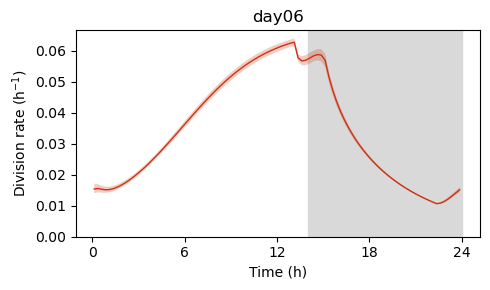

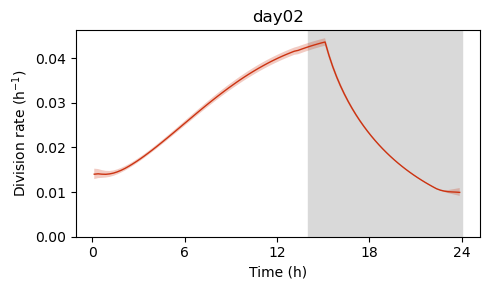

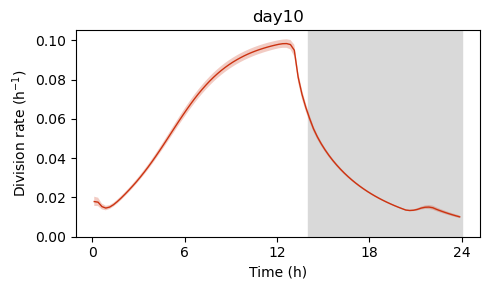

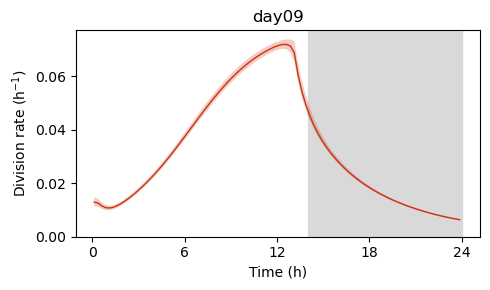

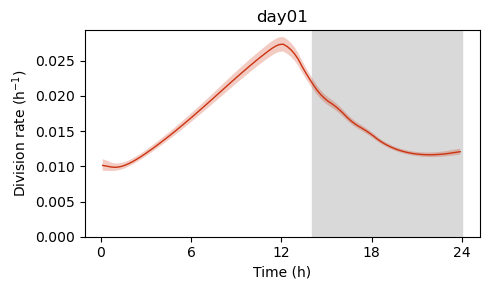

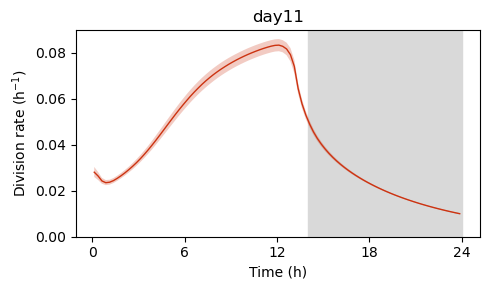

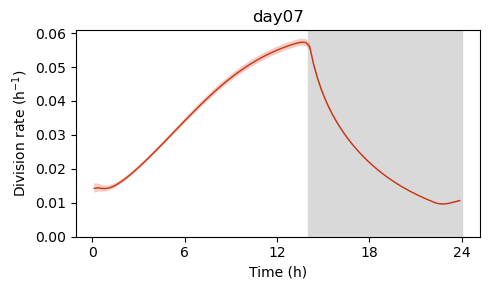

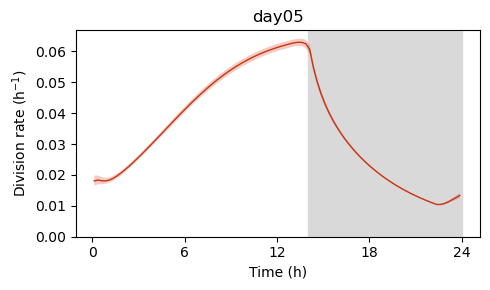

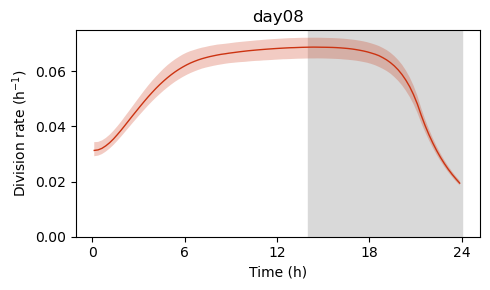

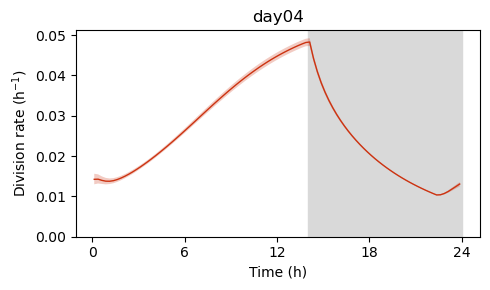

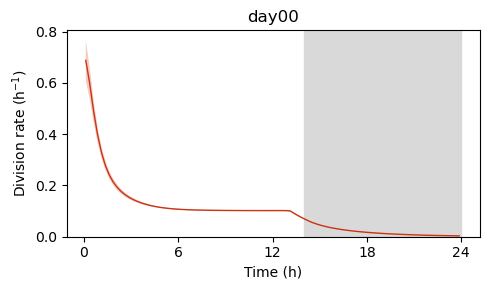

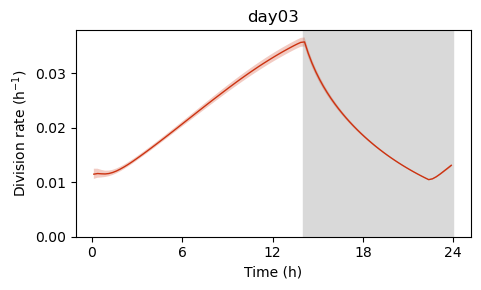

In [6]:
for file, day in zip(path_files, day_strs):
    ds = xr.open_dataset(file, group="m_pmb_sigprior_v2", decode_times=False)
    # Extract arrays — adjust variable names to match your dataset
    cell_count = ds["cell_count"].values   # shape (n_samples, n_time) e.g. (6000, 97)
    t = ds["time"].values / 60.0           # convert minutes → hours, shape (97,)
    dt_h = (t[1] - t[0])                  # time step in hours

    # --- Compute division rate  ---
    # Instantaneous rate between consecutive time steps → shape (6000, 96)
    plotprop = (np.log(cell_count[:, 1:]) - np.log(cell_count[:, :-1])) / (t[1:] - t[:-1])
    x = 0.5 * (t[1:] + t[:-1])           # midpoint times, shape (96,)

    # --- Compute percentiles across samples (axis=0) ---
    qq = np.percentile(plotprop, q=(5, 25, 50, 75, 95), axis=0)  # shape (5, 96)

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(5, 3))

    color = "#cc3311"

    ax.fill_between(x, qq[1, :], qq[3, :], alpha=0.25, facecolor=color)  # 25–75% IQR
    ax.plot(x, qq[2, :], color=color, lw=1)                               # median

    ax.set_ylim(bottom=0.0)
    ax.set_ylabel("Division rate (h$^{-1}$)")
    ax.set_xlabel("Time (h)")
    ax.set_xticks(np.linspace(0, t[-1], 5).astype(int))

    #shade dark periods for diel 
    ax.axvspan(14, 24, color='0.85', zorder=-1)

    # add title
    ax.set_title(day)
    plt.tight_layout()
    plt.show()

### Diagnostics
- rhat_max = model convergence
- delta / delta_max = probability of division given the size
    - Can use the delta function to see how the probability could change over time throughout the cruise
    - plot median over time of day, what time of day do we have the highest proportion of cells dividing
- gamma = growth (carbon fixation)
- check if Ek values are realistic

Division
- Daily rates are good, be cautious with timing of division

3 processes driving Qc:
- division, fixation, respiration

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.001865])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.002


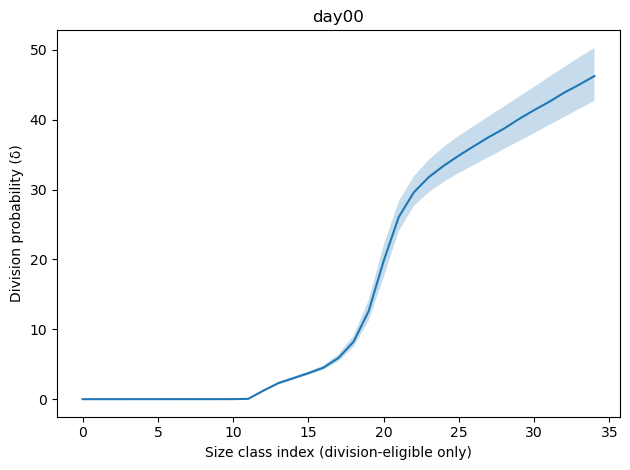

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.000937])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.001


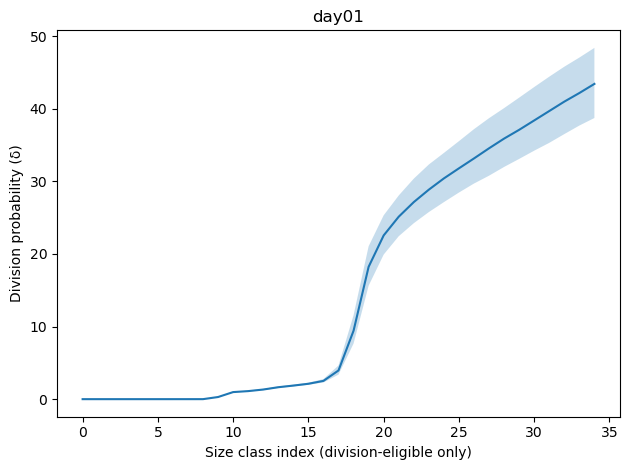

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.002639])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.003


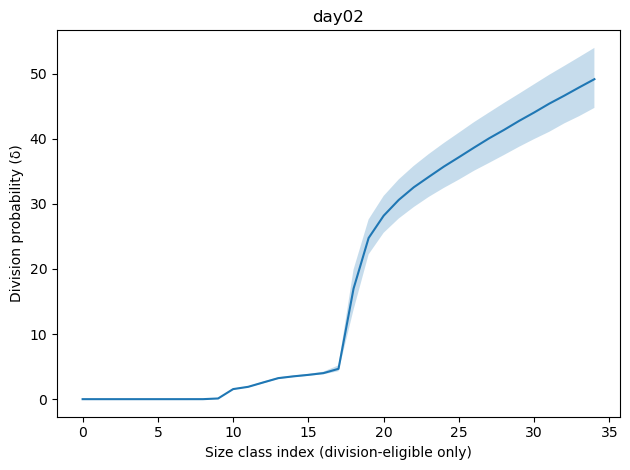

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.002019])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.002


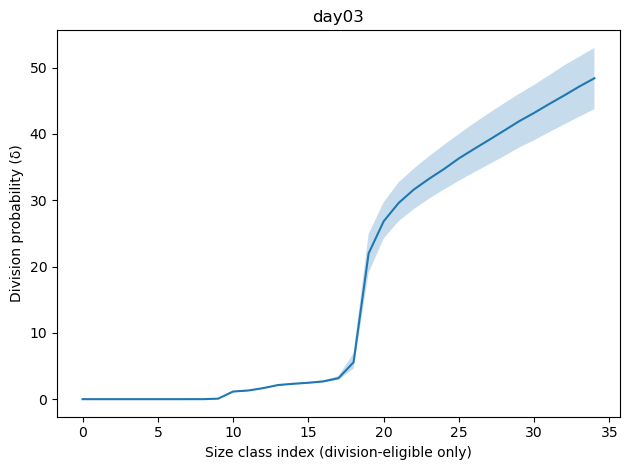

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.001119])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.001


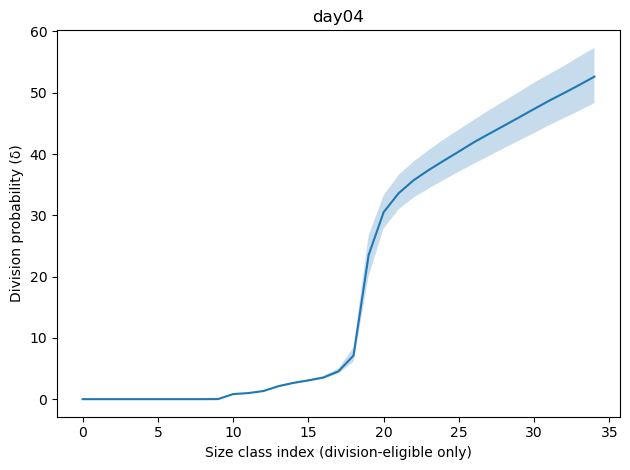

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.003681])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.004


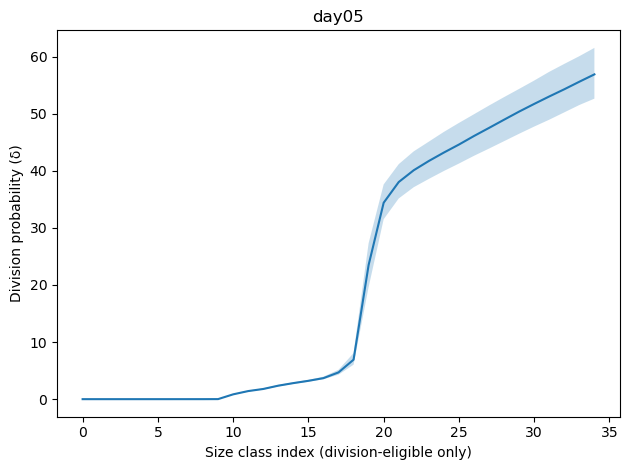

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.003641])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.004


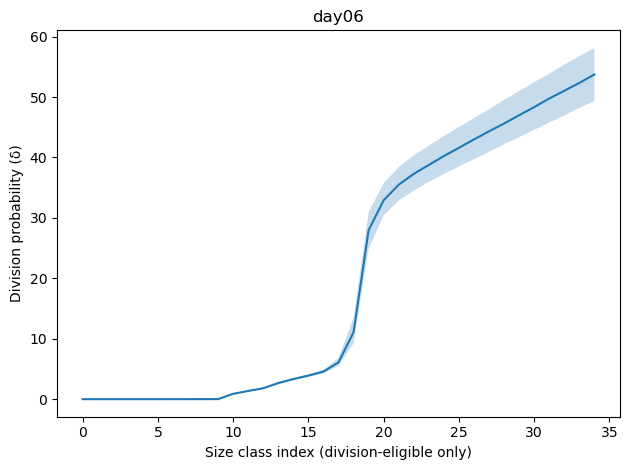

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.002142])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.002


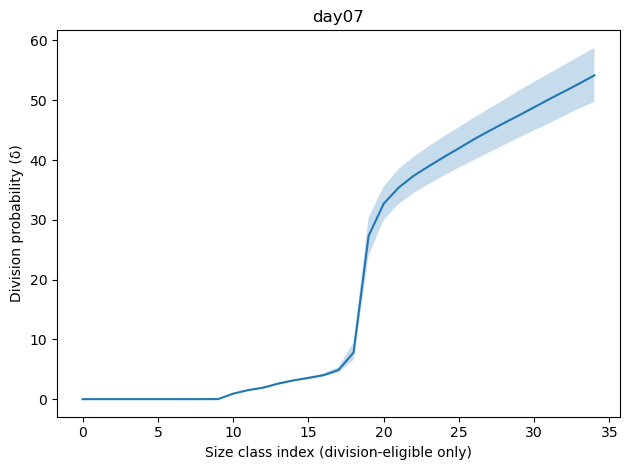

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([22.980909])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 22.98


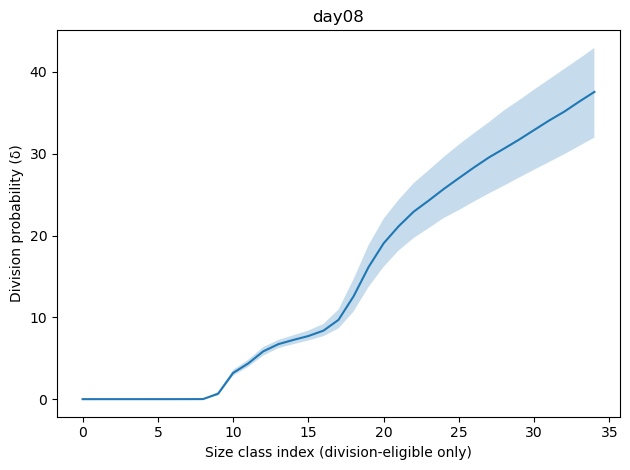

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.001739])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.002


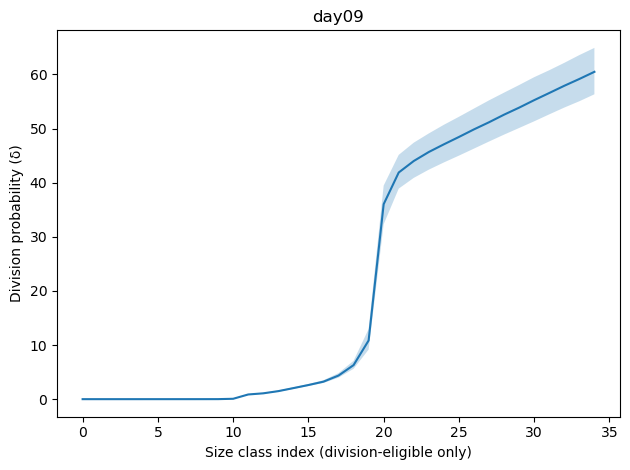

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.001576])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.002


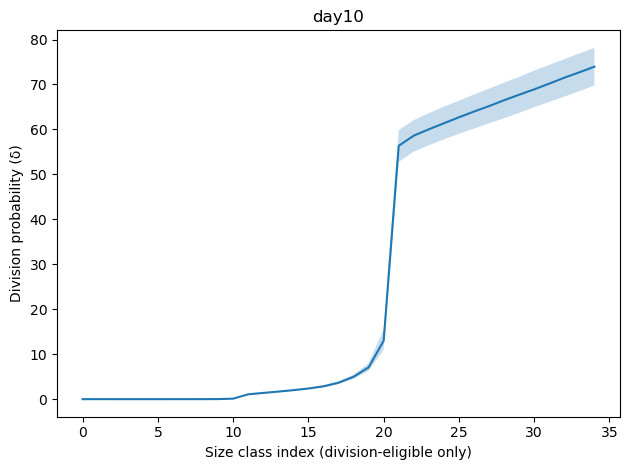

<xarray.DataArray 'rhat_max' (rhat_max: 1)> Size: 8B
array([1.005428])
Coordinates:
  * rhat_max  (rhat_max) float64 8B 1.005


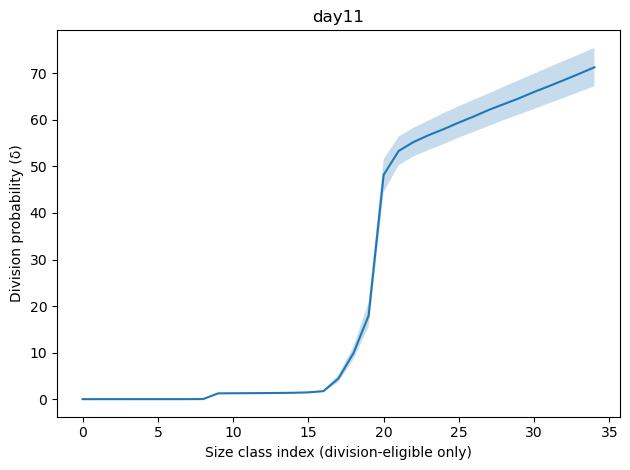

In [59]:
# save as pandas dfs 
delta_dfs = []
for file, day in zip(np.sort(path_files), np.sort(day_strs)):
    ds = xr.open_dataset(file, group="m_pmb_sigprior_v2", decode_times=False)
    # convert to df
    df = ds['delta'].to_dataframe().reset_index()
    df['day'] = day
    # save 
    delta_dfs.append(df)
    # --- Compute percentiles across each size class (axis=0) ---
    delta = ds["delta"].values  # shape (6000, 35)
    # print model convergence score
    print(ds['rhat_max'])
    qq = np.percentile(delta, q=(25, 50, 75), axis=0)  # shape (3, 35)

    ### Plot
    fig, ax = plt.subplots()
    ax.fill_between(range(35), qq[0], qq[2], alpha=0.25)
    ax.plot(range(35), qq[1], lw=1.5)
    ax.set_xlabel("Size class index (division-eligible only)")
    ax.set_ylabel("Division probability (δ)")

    # add title
    ax.set_title(day)
    plt.tight_layout()
    plt.show()

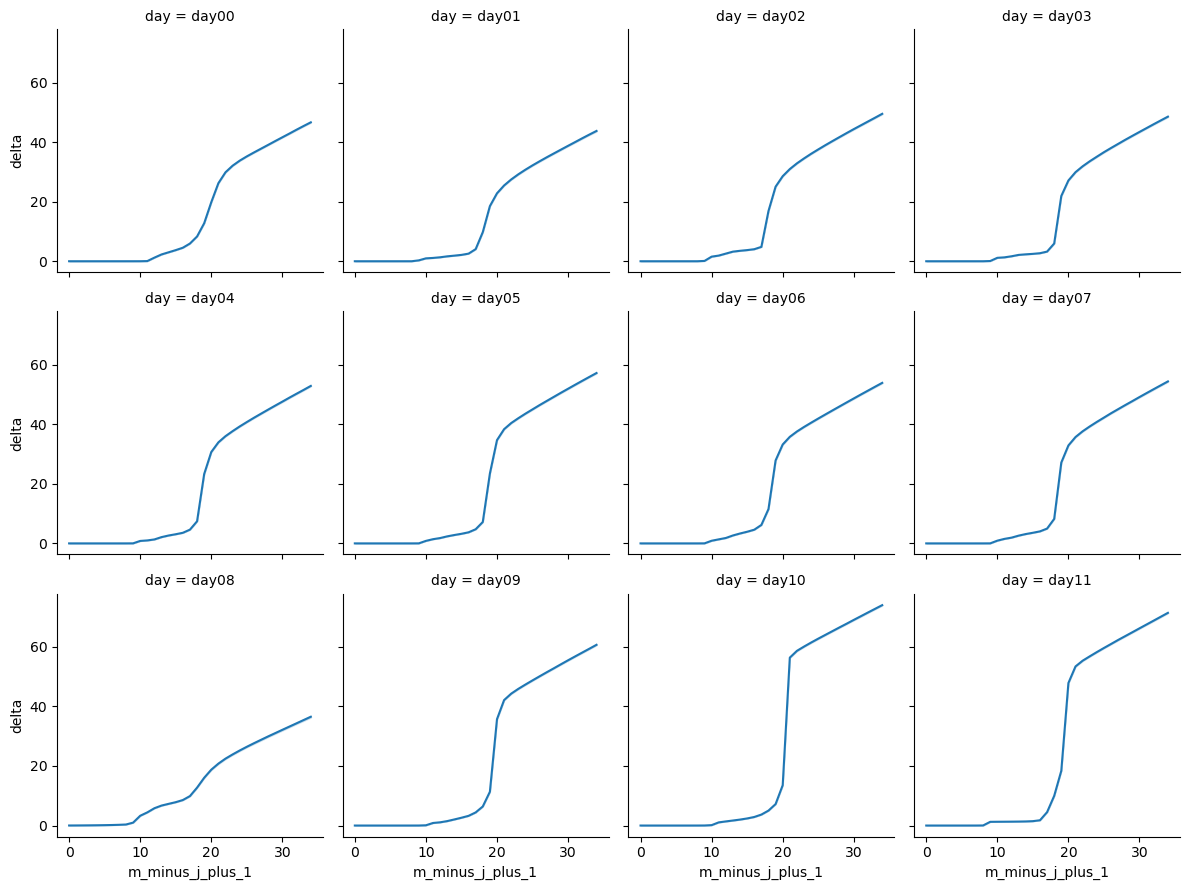

In [61]:
all_deltas = pd.concat(delta_dfs).reset_index(drop = True)

### create a facet grid version
g = sns.FacetGrid(all_deltas, col="day", col_wrap = 4)
g.map(sns.lineplot, 'm_minus_j_plus_1', 'delta')

### How is the probability of division changing over time for each size bin?
- $v_{min}$ is smallest Qc bin
- delta_v_inv is # size classes per doubling of cell volume
- m is total # size classes from 0 -1
-  m_minus_j_plus_1 should actually be offset by 8 (cells that are in the bottom 8 size classes cannot divide)
- obs_count has the number of cells per hour (columns) for each size bin (rows)

In [62]:
np.sort(path_files)[6]

np.str_('../data/SCOPE_6-mpm_results/SCOPE_6/SCOPE_6/SCOPE_6_day06_22hours_2015-07-30T16:00:00+00:00_2015-07-31T15:00:00+00:00.nc')

In [63]:
# Choose a test file
file = np.sort(path_files)[6]    # day 4 vs 9
ds = xr.open_dataset(file, group="m_pmb_sigprior_v2", decode_times=False)
delta = ds["delta"].values  # shape (6000, 35)
qq = np.percentile(delta, q=(25, 50, 75), axis=0)  # shape (3, 35)

psd_bins = pd.read_parquet('../data/SCOPE_6.grid_bins.parquet')
psd_grid = pd.read_parquet('../data/SCOPE_6.hourly_gridded.parquet')

# subset to just a test 
# day 6
start_date = '2015-07-30T16:00:00+00:00'
end_date = '2015-07-31T15:00:00+00:00'

### day 4
# start_date = '2015-07-28T16:00:00+00:00'
# end_date = '2015-07-29T15:00:00+00:00'
### day 9 
# start_date = '2015-08-02T16:00:00+00:00'
# end_date = '2015-08-03T15:00:00+00:00'
test_grid = psd_grid.loc[(psd_grid['date'] >= start_date) & 
                         (psd_grid['date'] < end_date)].reset_index(drop = True)

pro_grid = test_grid.loc[(test_grid['pop'] == 'prochloro')].reset_index(drop = True)

## getting size classes (this is from bayesian mpm figures notebook)
v_min        = ds["v_min"].item()          # scalar float
delta_v_inv  = ds["delta_v_inv"].item()    # scalar float
m            = int(ds["m"].item())         # scalar int
# calculate the inverse of number of size classes that can double
delta_v = 1.0 / delta_v_inv
# get the left values of size bins
v        = v_min * 2**(np.arange(m) * delta_v)
# these are the centered discret size classes
v_carbon = v * np.sqrt(2**(delta_v))

# percentiles from last run are from last day (day 11)- just use the 50 percentile for now
# index of each qq val should map to size class
delta_df = pd.DataFrame(qq[1], columns=['delta'])
# these are size classes that can divide
div_size = v_carbon[delta_v_inv:]

<Axes: xlabel='time', ylabel='loss'>

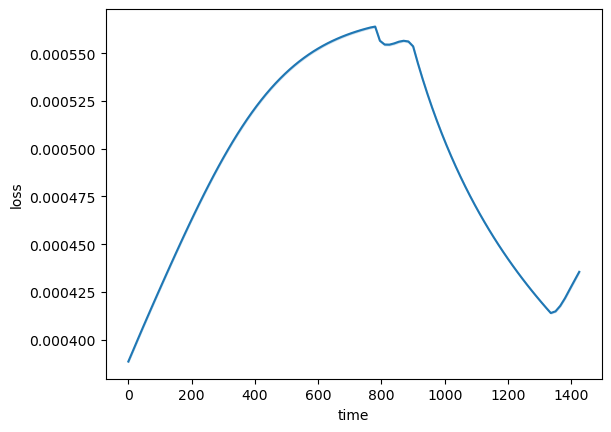

In [65]:
# try to estimate carbon loss here
dt_h = ds['dt'] / 60
# i think this is hourly loss
hourly_loss = ds['resp_size_loss'][:, :-1] / ds['cell_count'][:, :-1] / dt_h

# plot over time
loss_df = hourly_loss.to_dataframe(name = 'loss').reset_index()
sns.lineplot(loss_df, x = 'time', y = 'loss')

<Axes: ylabel='Count'>

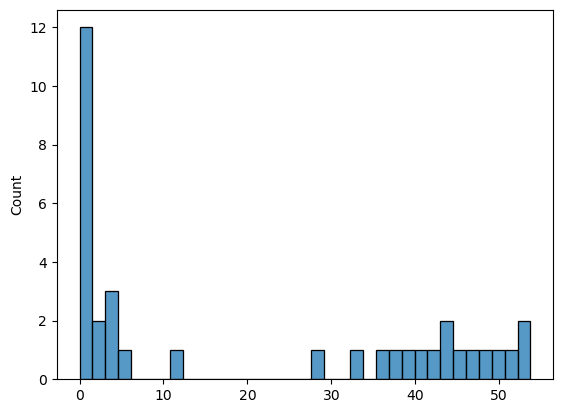

In [64]:
## let's plot the distribution of deltas and choose a threshold
sns.histplot(qq[1], bins = 35)
## looks very disjoint– for now, i'm just gonna go with 20%

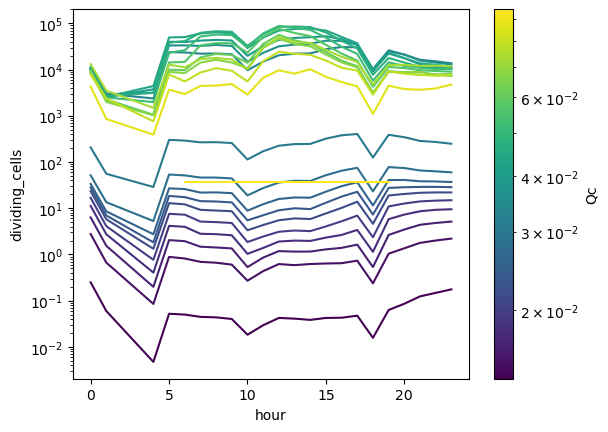

In [542]:
## plot each size class division count over time
# convert to pandas df
obs_df = ds['obs_count'].to_dataframe().reset_index()
# make column for hour
obs_df['hour'] = obs_df['obstime'] / 60
# subset for only dividing classes (≥ 8)
div_obs = obs_df.loc[obs_df['sizeclass'] >= 8]

# make df for size classes, Qc, and delta percentiles
size_deltas = pd.DataFrame(data = list(zip(range(delta_v_inv, len(ds['obs_count'])), div_size, qq[0], qq[1], qq[2])), 
             columns = ['sizeclass', 'Qc', 'delta25', 'delta50', 'delta75'])
# merge 
merge_deltas = div_obs.merge(size_deltas)
# calculate counts per size class
merge_deltas['dividing_cells'] = merge_deltas['delta50'] * merge_deltas['obs_count']
# don't count size classes with no values
merge_deltas = merge_deltas.loc[merge_deltas['dividing_cells'] > 0]


from matplotlib.colors import LogNorm
import matplotlib.ticker as ticker
#### plot 
fig, axs = plt.subplots()
# Define logarithmic normalization
norm = LogNorm(vmin=merge_deltas['Qc'].min(), vmax=merge_deltas['Qc'].max())
# add to line plot
sns.lineplot(merge_deltas, x = 'hour', y = 'dividing_cells', hue = 'Qc',
              hue_norm = norm, palette = 'viridis', legend = False)
# try to log scale y
axs.set_yscale('log')
# map colorbar to plot
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
# sm.set_array([])
cbar = axs.figure.colorbar(sm, ax=axs, label='Qc')
cbar.ax.yaxis.set_major_formatter(ticker.ScalarFormatter()) 
# # Set ticks at specific values across your data range
# cbar.set_ticks([0.015, 0.05, 0.15])               # adjust to match your data range
# cbar.set_ticklabels(['0.01', '0.05', '0.1'])   # format however you like

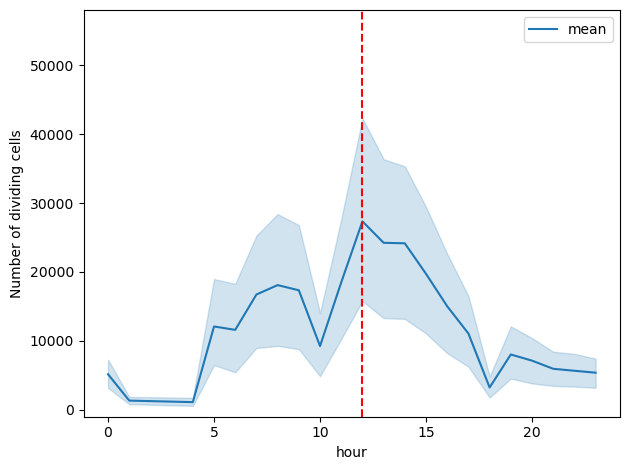

In [543]:
## plot each size class division count over time for deltas ≥ 20
delta_lim = np.mean(qq[1])
# subset for over the trhdshold and no zeros
sub_deltas = merge_deltas.loc[(merge_deltas['delta50'] > delta_lim)]
# plot aggregated deltas over time of one day
fig, axs = plt.subplots()
sns.lineplot(merge_deltas, x = 'hour', y = 'dividing_cells', estimator='mean', ax = axs, label = 'mean')
# add line for maximum hour of most division
hourly_means = merge_deltas.groupby(['hour'])['dividing_cells'].mean().reset_index()
max_hour = hourly_means.loc[hourly_means['dividing_cells'] == 
                 np.max(hourly_means['dividing_cells']), 'hour'].values[0]
# add line to show peak
axs.axvline(x = max_hour, linestyle = '--', c = 'r')
axs.set_ylim(-1000, 58000)
axs.set_ylabel("Number of dividing cells")

plt.tight_layout()

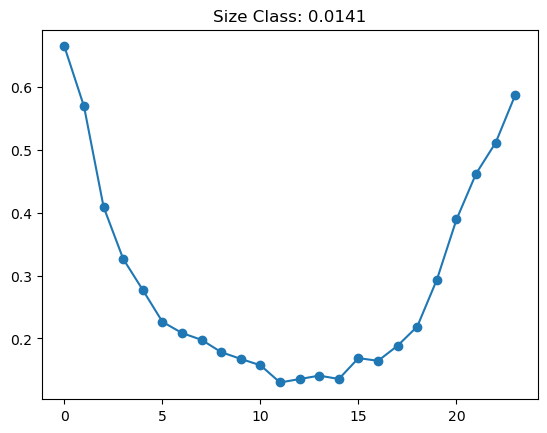

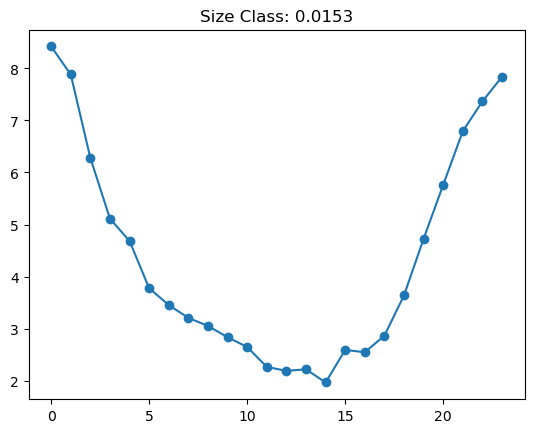

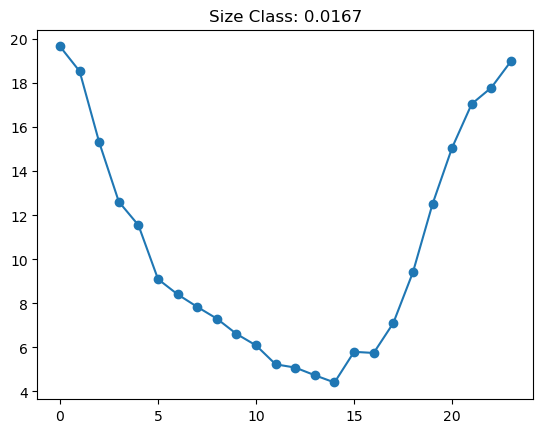

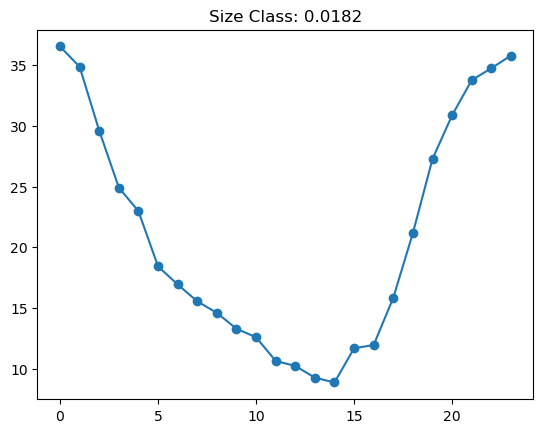

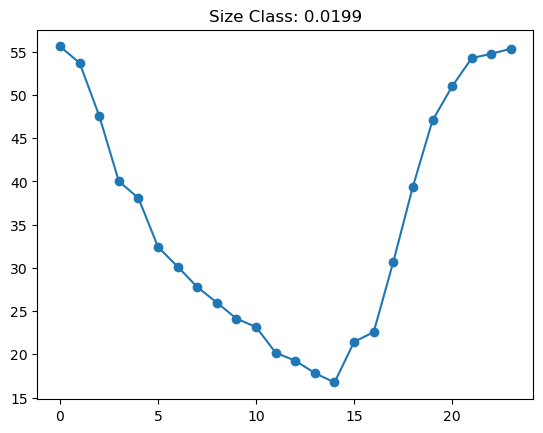

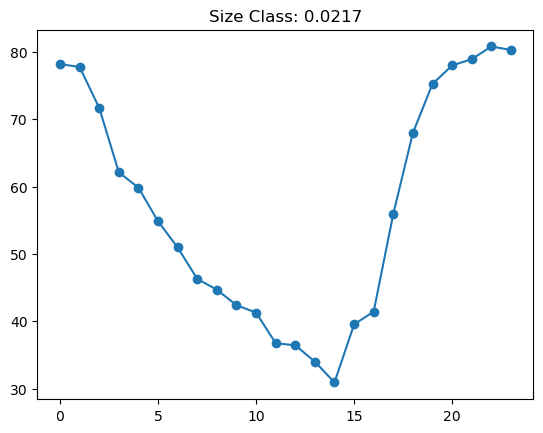

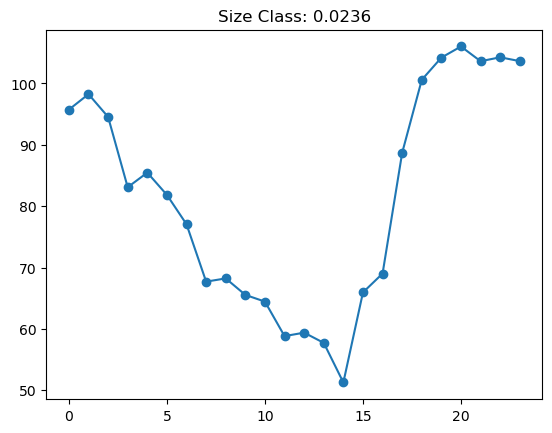

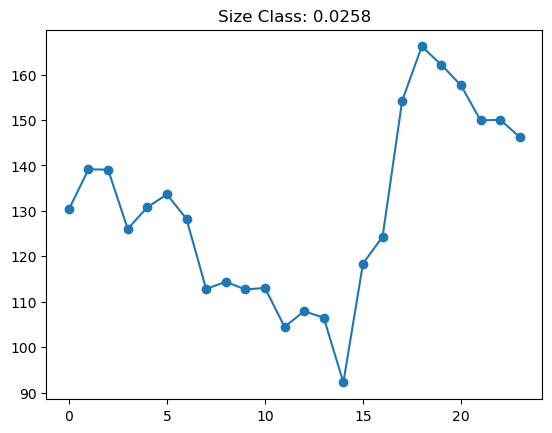

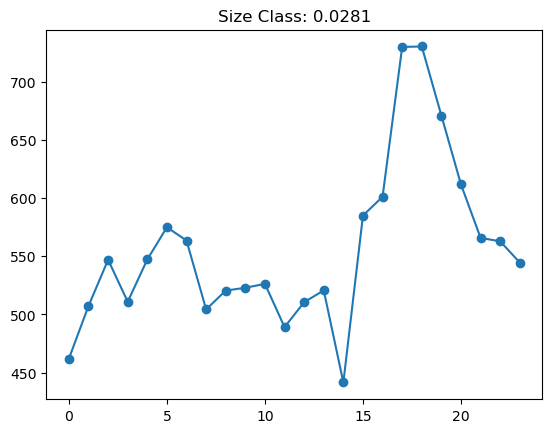

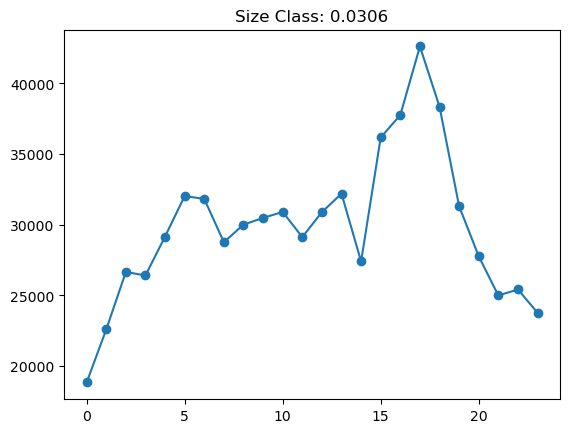

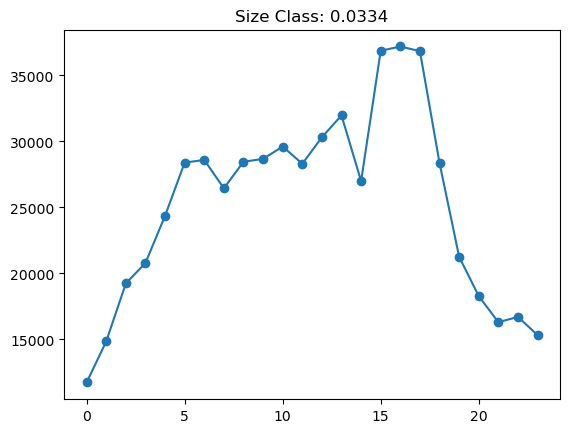

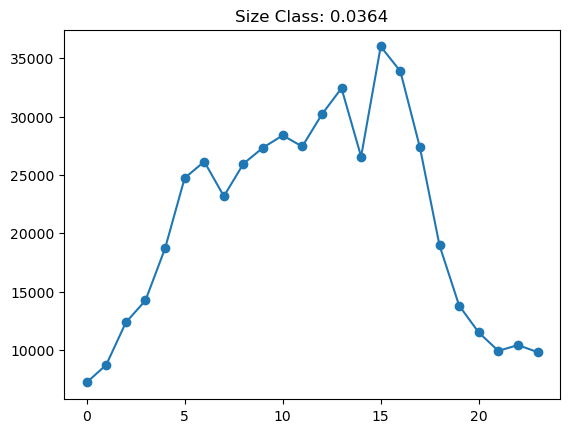

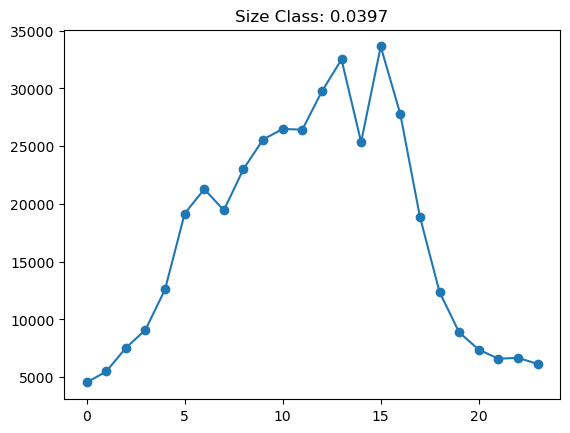

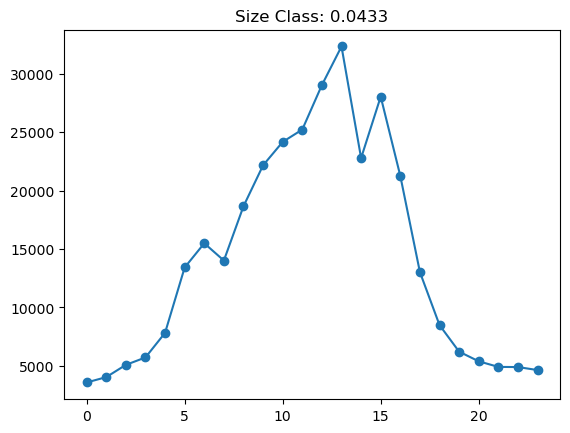

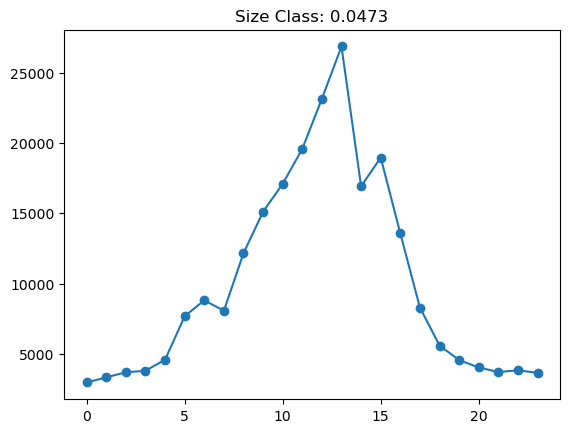

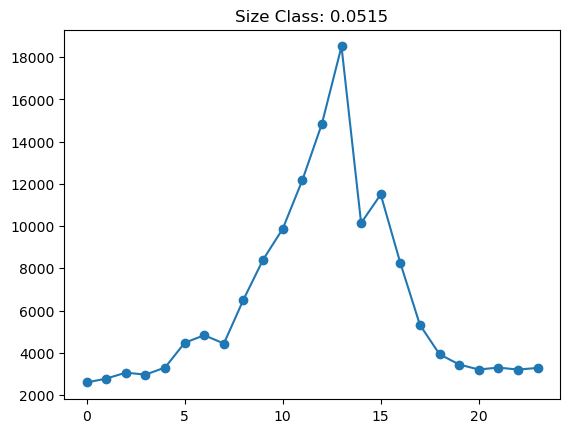

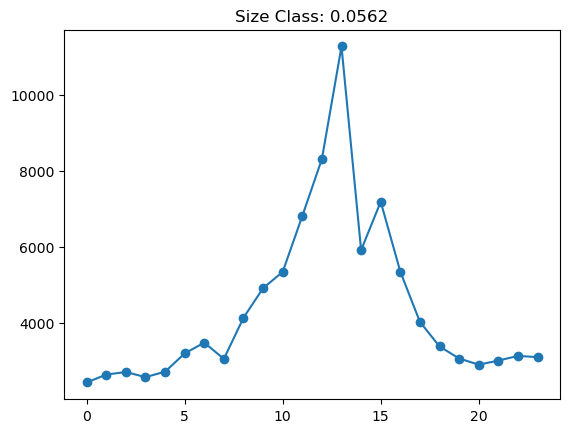

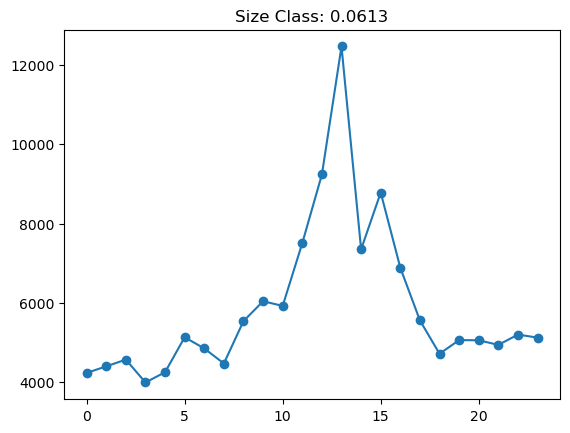

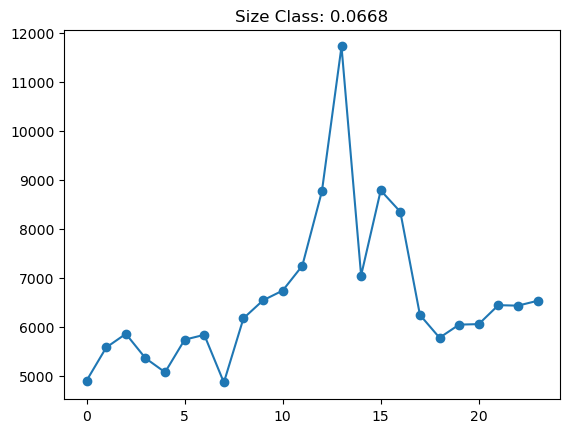

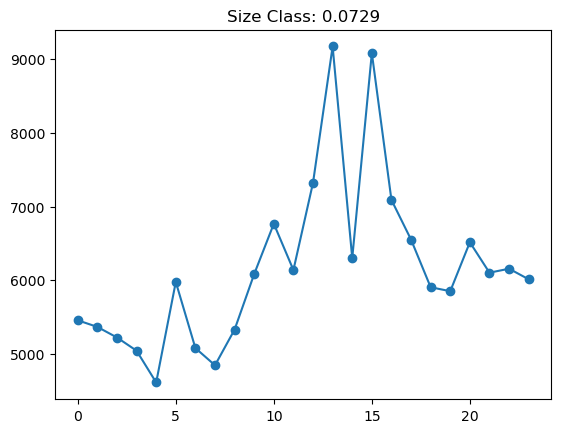

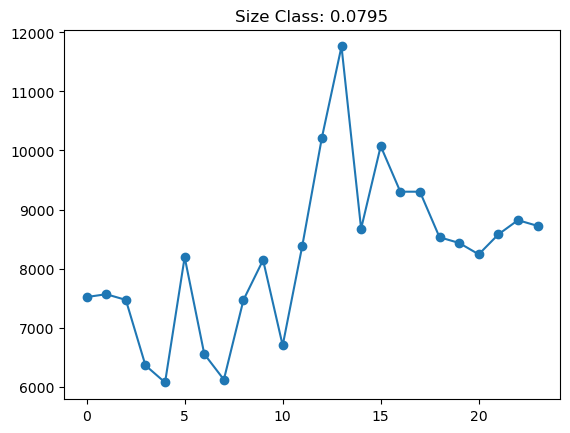

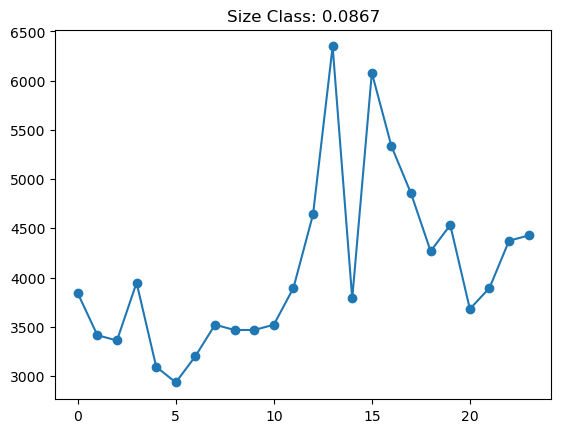

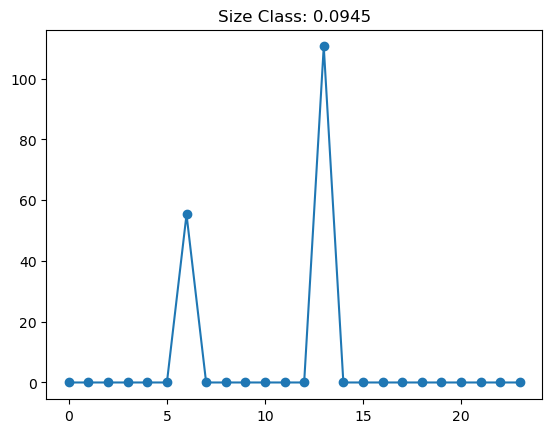

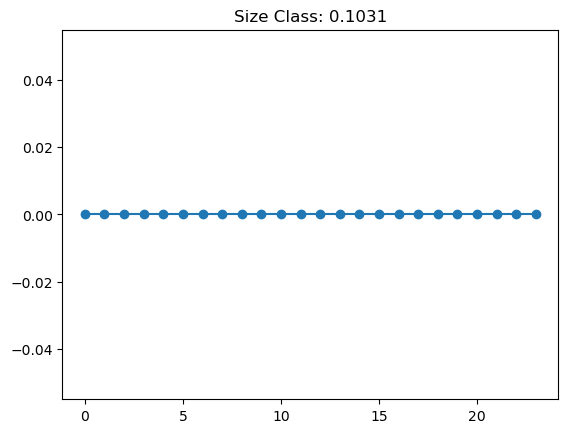

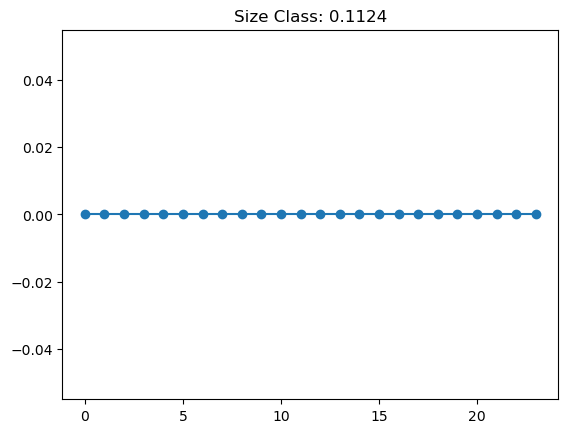

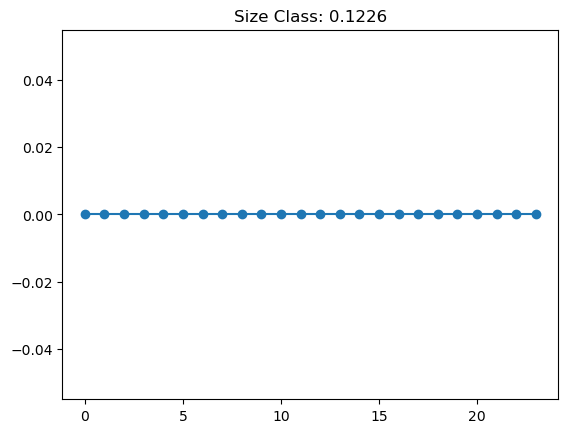

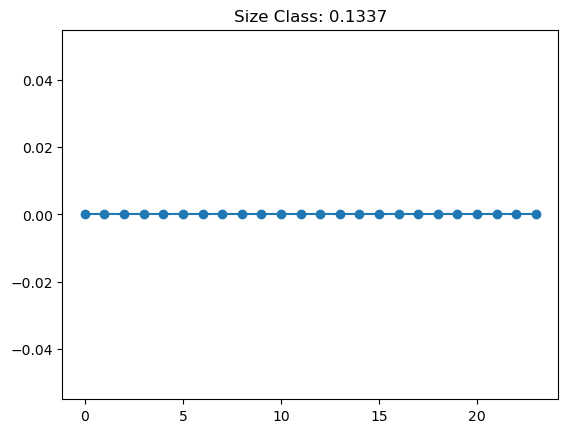

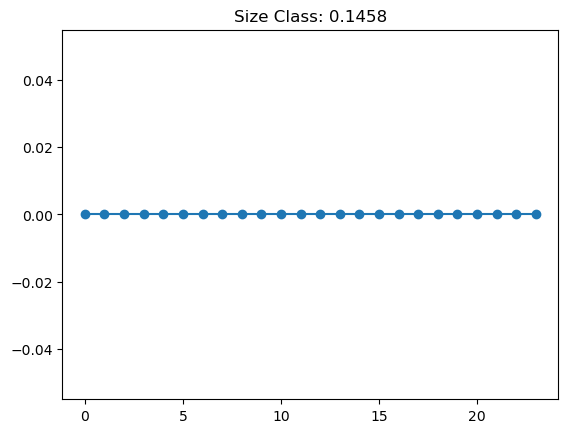

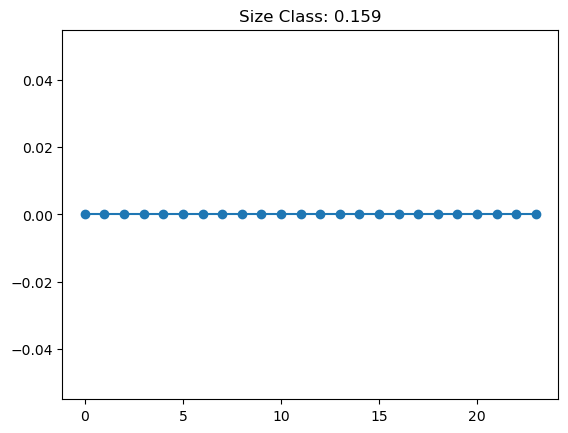

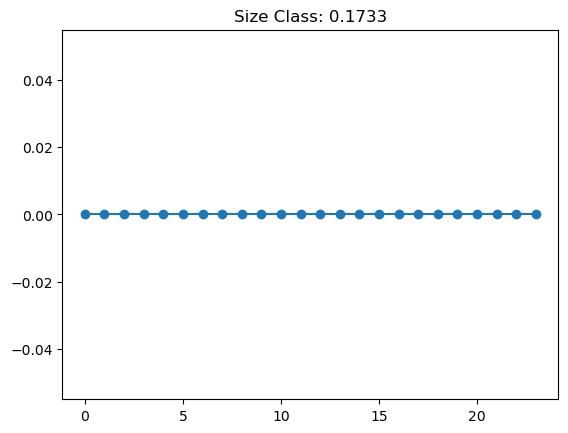

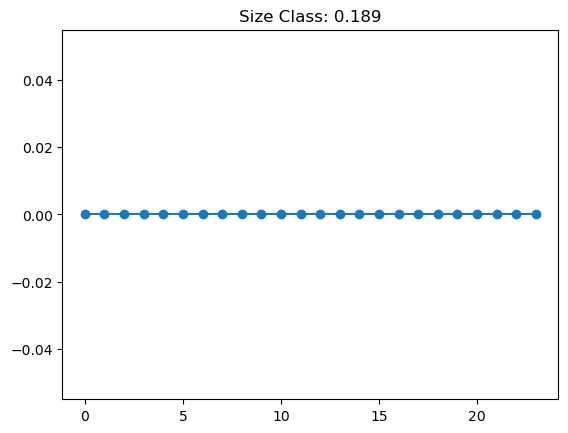

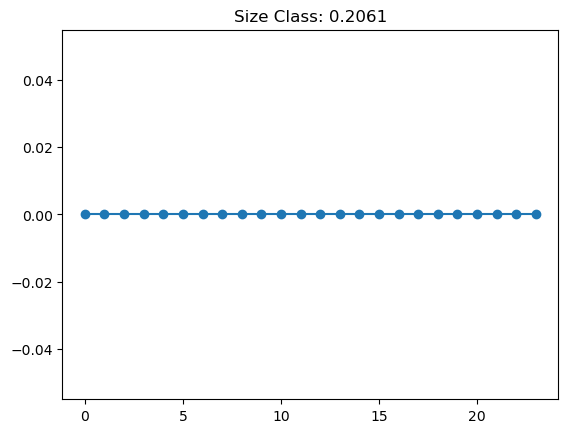

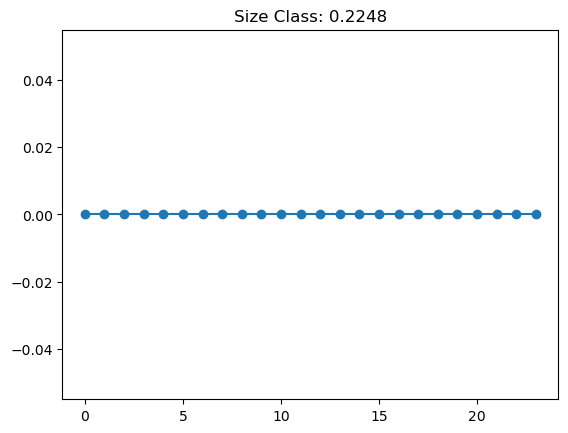

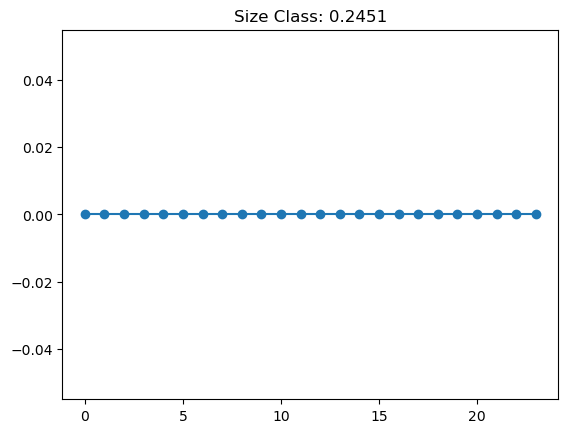

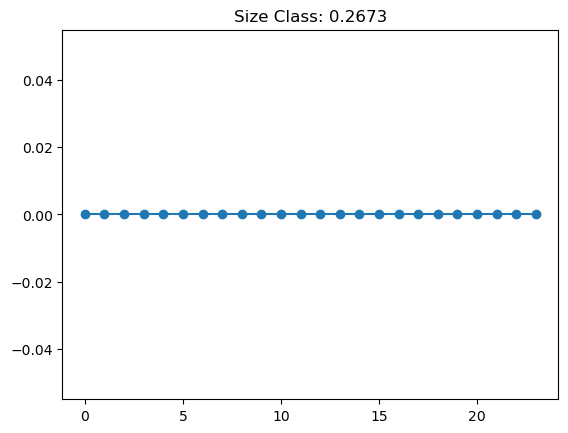

In [ ]:
# loop through each size class
for obs_ind, size, delta in zip(range(delta_v_inv, len(ds['obs_count'])), div_size, qq[1]) :
    # get list of observations per size 
    obs_list = ds['obs_count'][obs_ind].values
    # print(f'Size bin: {size}')
    # print(obs_list * delta)
    ## plot the number of cells that divide based on delta probability for each hour
    fig, axs = plt.subplots()
    x = np.arange(len(obs_list))
    y = obs_list * delta
    axs.plot(x, y, marker = 'o')
    axs.set_title(f'Size Class: {np.round(size, 4)}')

In [538]:
ds#['exponent_gamma']

<xarray.Dataset> Size: 72MB
Dimensions:           (sizeclass: 43, obstime: 21, time: 97, sample: 6000,
                       m_minus_j_plus_1: 35, rhat_max: 1)
Coordinates:
  * obstime           (obstime) int64 168B 0 60 120 360 ... 1200 1260 1320 1380
  * time              (time) int64 776B 0 15 30 45 60 ... 1395 1410 1425 1440
  * rhat_max          (rhat_max) float64 8B 1.002
Dimensions without coordinates: sizeclass, sample, m_minus_j_plus_1
Data variables: (12/24)
    dt                int64 8B ...
    m                 int64 8B 43
    v_min             float64 8B 0.006727
    delta_v_inv       int64 8B 8
    obs               (sizeclass, obstime) float64 7kB ...
    i_test            (obstime) int64 168B ...
    ...                ...
    cell_count        (sample, time) float64 5MB ...
    sigma             (sample) float64 48kB ...
    divrate           (sample) float64 48kB ...
    mod_obspos        (sample, sizeclass, obstime) float64 43MB ...
    w_ini             (sample, sizeclass) float64 2MB ...
    rho_max           (sample) float64 48kB ...
Attributes:
    code:     m_pmb_sigprior_v2.stan

what is the size class at which delta exceeds my defined threshold
- max of first order deriv

#### Plot division rate over the day

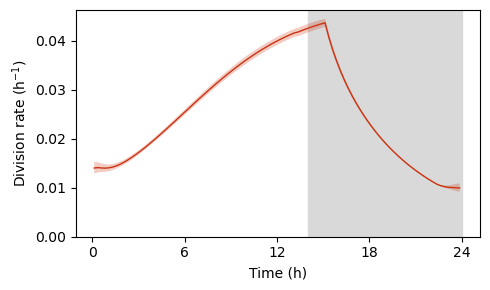

In [42]:
import matplotlib.gridspec as gridspec

# Extract arrays — adjust variable names to match your dataset
cell_count = ds["cell_count"].values   # shape (n_samples, n_time) e.g. (6000, 97)
t = ds["time"].values / 60.0           # convert minutes → hours, shape (97,)
dt_h = (t[1] - t[0])                  # time step in hours

# --- Compute division rate (same formula as notebook) ---
# Instantaneous rate between consecutive time steps → shape (6000, 96)
plotprop = (np.log(cell_count[:, 1:]) - np.log(cell_count[:, :-1])) / (t[1:] - t[:-1])
x = 0.5 * (t[1:] + t[:-1])           # midpoint times, shape (96,)

# --- Compute percentiles across samples (axis=0) ---
qq = np.percentile(plotprop, q=(5, 25, 50, 75, 95), axis=0)  # shape (5, 96)

# --- Plot ---
fig, ax = plt.subplots(figsize=(5, 3))

color = "#cc3311"

ax.fill_between(x, qq[1, :], qq[3, :], alpha=0.25, facecolor=color)  # 25–75% IQR
ax.plot(x, qq[2, :], color=color, lw=1)                               # median

ax.set_ylim(bottom=0.0)
ax.set_ylabel("Division rate (h$^{-1}$)")
ax.set_xlabel("Time (h)")
ax.set_xticks(np.linspace(0, t[-1], 5).astype(int))

#shade dark periods if you have a diel experiment
ax.axvspan(14, 24, color='0.85', zorder=-1)

plt.tight_layout()
plt.show()